In [1]:
import os, glob
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!date
!python --version
!nvidia-smi
import torch
print("PyTorch version:", torch.__version__, "| GPU ready:", torch.cuda.is_available())

Sat Oct 17 11:19:33 PM UTC 2026
Python 3.13.15
Sat Oct 17 23:19:33 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   35C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+

In [2]:
# Automatically finding '8410/Ass1/Assignment 1' folder in Google Drive
matches = glob.glob('/content/drive/MyDrive/3rd_sem/8410/Ass1/Assignment 1', recursive=True)
if not matches:
    matches = glob.glob('/content/drive/MyDrive/3rd_sem/8410/Ass1/Assignment 1', recursive=True)
BASE_DIR = matches[0]
EVAL_DIR = os.path.join(BASE_DIR, '60801131_Evaluation')
os.makedirs(EVAL_DIR, exist_ok=True)
os.chdir(EVAL_DIR)
print("Working folder set to:", os.getcwd())

Working folder set to: /content/drive/MyDrive/3rd_sem/8410/Ass1/Assignment 1/60801131_Evaluation


# Pair 1 (Week 2): Prompt-to-Prompt vs StyleAligned on shared U-Net

100%|██████████| 26.4M/26.4M [00:02<00:00, 10.2MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 210kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.78MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 29.1MB/s]


data loaded: torch.Size([2048, 1, 28, 28]) torch.Size([512, 1, 28, 28]) | first 4 test labels: ['Ankle boot', 'Pullover', 'Trouser', 'Trouser']
base warmup loss: 0.0397
[Pair 1 | System 1] Prompt-to-Prompt (prototype)         | TestMSE: 0.01218 | PertMSE: 0.02804 | Drift: 0.01894 | Lat(batch_64): 6.513ms
[Pair 1 | System 2] StyleAligned (prototype)             | TestMSE: 0.01190 | PertMSE: 0.02745 | Drift: 0.01887 | Lat(batch_64): 4.170ms


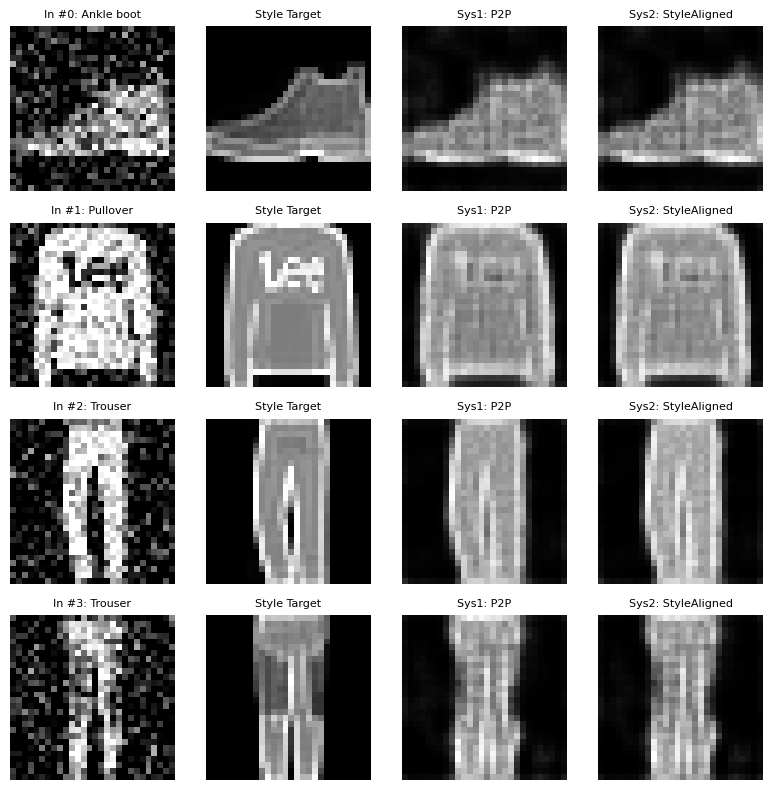

In [3]:

import sys, os, time, math, copy, importlib
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import pandas as pd

if "src" not in sys.path:
    sys.path.insert(0, os.path.abspath("src"))

import profiler, w2_editing
importlib.reload(profiler)
importlib.reload(w2_editing)

from profiler import DEVICE, CLASS_NAMES, load_fashion_data, compute_error_stats, record_run
from w2_editing import make_style_edit_targets, SharedAttentionEditUNet

def now():
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    return time.perf_counter()

x_tr, y_tr, x_te, y_te = load_fashion_data()
print("data loaded:", x_tr.shape, x_te.shape, "| first 4 test labels:", [CLASS_NAMES[int(c)] for c in y_te[:4]])

y_tr_style = make_style_edit_targets(x_tr)
y_te_style = make_style_edit_targets(x_te)

# pretrain one shared U-Net on both source (0..9) and style-edited (10..19) prompts
torch.manual_seed(42)
base_unet = SharedAttentionEditUNet().to(DEVICE)
opt_base = torch.optim.AdamW(base_unet.parameters(), lr=2e-3)

for step in range(50):
    idx = torch.randint(0, x_tr.size(0), (64,), device=DEVICE)
    xb = torch.clamp(x_tr[idx] + 0.25 * torch.randn_like(x_tr[idx]), 0.0, 1.0)
    out_src, _ = base_unet.forward_base(xb, y_tr[idx])
    out_edt, _ = base_unet.forward_base(xb, y_tr[idx] + 10)
    loss_b = F.mse_loss(out_src, x_tr[idx]) + F.mse_loss(out_edt, y_tr_style[idx])
    opt_base.zero_grad(); loss_b.backward(); opt_base.step()

print("base warmup loss:", round(loss_b.item(), 4))

# clone base weights so both attention methods start from the exact same checkpoint
p2p_net = copy.deepcopy(base_unet)
sa_net = copy.deepcopy(base_unet)

opt_p2p = torch.optim.AdamW(p2p_net.parameters(), lr=1e-3)
opt_sa = torch.optim.AdamW(sa_net.parameters(), lr=1e-3)

# style reference sample from training split
ref_img = y_tr_style[0:1]
ref_cls = y_tr[0:1]

# System 1: Prompt-to-Prompt (inject source self-attention map into edited pass)
t0 = now()
for _ in range(60):
    idx = torch.randint(0, x_tr.size(0), (64,), device=DEVICE)
    xb = torch.clamp(x_tr[idx] + 0.25 * torch.randn_like(x_tr[idx]), 0.0, 1.0)
    l1 = F.mse_loss(p2p_net.forward_prompt_to_prompt(xb, y_tr[idx], inject_weight=0.85), y_tr_style[idx])
    opt_p2p.zero_grad(); l1.backward(); opt_p2p.step()
t_p2p = now() - t0

# System 2: StyleAligned (share self-attention K, V with reference style image)
t0 = now()
for _ in range(60):
    idx = torch.randint(0, x_tr.size(0), (64,), device=DEVICE)
    xb = torch.clamp(x_tr[idx] + 0.25 * torch.randn_like(x_tr[idx]), 0.0, 1.0)
    l2 = F.mse_loss(sa_net.forward_style_aligned(xb, y_tr[idx], ref_img, ref_cls), y_tr_style[idx])
    opt_sa.zero_grad(); l2.backward(); opt_sa.step()
t_sa = now() - t0

p2p_net.eval(); sa_net.eval()
torch.manual_seed(99)
x_tr_eval = torch.clamp(x_tr[:512] + 0.25 * torch.randn_like(x_tr[:512]), 0.0, 1.0)
x_te_in = torch.clamp(x_te + 0.25 * torch.randn_like(x_te), 0.0, 1.0)
x_te_pert = torch.clamp(x_te + 0.50 * torch.randn_like(x_te), 0.0, 1.0)

if torch.cuda.is_available(): torch.cuda.reset_peak_memory_stats()
with torch.no_grad():
    t0 = now()
    for _ in range(20): _ = p2p_net.forward_prompt_to_prompt(x_te_in[:64], y_te[:64])
    lat_p2p = (now() - t0) * 1000.0 / 20.0
    tr_mse_p2p = F.mse_loss(p2p_net.forward_prompt_to_prompt(x_tr_eval, y_tr[:512]), y_tr_style[:512]).item()
    out_te_p2p = p2p_net.forward_prompt_to_prompt(x_te_in, y_te)
    out_pert_p2p = p2p_net.forward_prompt_to_prompt(x_te_pert, y_te)
vram_p2p = (torch.cuda.max_memory_allocated() / (1024**2)) if torch.cuda.is_available() else 0.0

if torch.cuda.is_available(): torch.cuda.reset_peak_memory_stats()
with torch.no_grad():
    t0 = now()
    for _ in range(20): _ = sa_net.forward_style_aligned(x_te_in[:64], y_te[:64], ref_img, ref_cls)
    lat_sa = (now() - t0) * 1000.0 / 20.0
    tr_mse_sa = F.mse_loss(sa_net.forward_style_aligned(x_tr_eval, y_tr[:512], ref_img, ref_cls), y_tr_style[:512]).item()
    out_te_sa = sa_net.forward_style_aligned(x_te_in, y_te, ref_img, ref_cls)
    out_pert_sa = sa_net.forward_style_aligned(x_te_pert, y_te, ref_img, ref_cls)
vram_sa = (torch.cuda.max_memory_allocated() / (1024**2)) if torch.cuda.is_available() else 0.0

st_p2p = compute_error_stats(out_te_p2p, y_te_style, out_pert_p2p, y_te_style, y_te, tr_mse_p2p)
st_sa = compute_error_stats(out_te_sa, y_te_style, out_pert_sa, y_te_style, y_te, tr_mse_sa)

cos_p2p = F.cosine_similarity(out_te_p2p.flatten(1), x_te.flatten(1), dim=-1).mean().item()
cos_sa = F.cosine_similarity(out_te_sa.flatten(1), x_te.flatten(1), dim=-1).mean().item()

record_run("Pair 1", "W2", "System 1", "Prompt-to-Prompt (prototype)", p2p_net, "batch_64", t_p2p, lat_p2p, vram_p2p, tr_mse_p2p, *st_p2p, aux_metric_name="Source_Cosine_Sim", aux_metric_val=cos_p2p)
record_run("Pair 1", "W2", "System 2", "StyleAligned (prototype)", sa_net, "batch_64", t_sa, lat_sa, vram_sa, tr_mse_sa, *st_sa, aux_metric_name="Source_Cosine_Sim", aux_metric_val=cos_sa)

fig, axes = plt.subplots(4, 4, figsize=(8, 8))
for i in range(4):
    lbl = CLASS_NAMES[int(y_te[i])]
    axes[i, 0].imshow(x_te_in[i, 0].cpu(), cmap="gray"); axes[i, 0].set_title(f"In #{i}: {lbl}", fontsize=8)
    axes[i, 1].imshow(y_te_style[i, 0].cpu(), cmap="gray"); axes[i, 1].set_title("Style Target", fontsize=8)
    axes[i, 2].imshow(out_te_p2p[i, 0].cpu(), cmap="gray"); axes[i, 2].set_title("Sys1: P2P", fontsize=8)
    axes[i, 3].imshow(out_te_sa[i, 0].cpu(), cmap="gray"); axes[i, 3].set_title("Sys2: StyleAligned", fontsize=8)
    for j in range(4): axes[i, j].axis("off")
plt.tight_layout()
plt.savefig("results/figures/pair1_w2_outputs.png", dpi=150)
plt.show()

# Pair 2 (Week 3): Custom Diffusion (token + W_K, W_V only) vs DreamBooth (full U-Net + CFG)

[Pair 2 | System 1] Custom Diffusion (prototype)         | TestMSE: 0.01771 | PertMSE: 0.03337 | Drift: 0.02694 | Lat(batch_64): 1.750ms
[Pair 2 | System 2] DreamBooth (prototype)               | TestMSE: 0.01533 | PertMSE: 0.03257 | Drift: 0.02833 | Lat(batch_64): 3.747ms


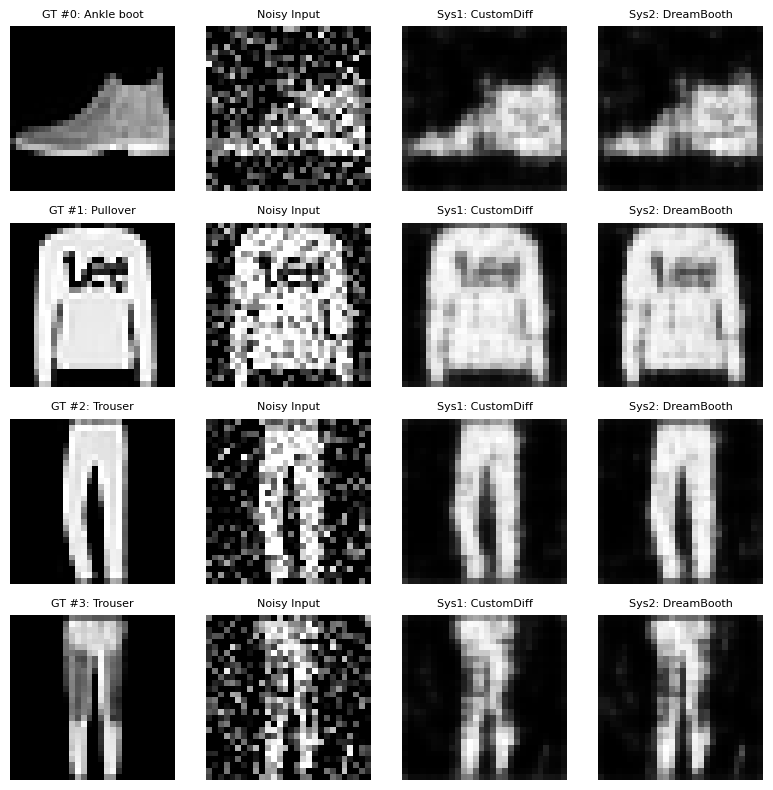

In [4]:
import w3_personalization
importlib.reload(w3_personalization)
from w3_personalization import CrossAttentionUNet2D

torch.manual_seed(42)
cust_model = CrossAttentionUNet2D().to(DEVICE)
db_model = CrossAttentionUNet2D().to(DEVICE)

# 30-step base warmup before freezing spatial conv layers for Custom Diffusion
opt_warm = torch.optim.AdamW(cust_model.parameters(), lr=2e-3)
for _ in range(30):
    idx = torch.randint(0, x_tr.size(0), (64,), device=DEVICE)
    xn = torch.clamp(x_tr[idx] + 0.35 * torch.randn_like(x_tr[idx]), 0.0, 1.0)
    l_w = F.mse_loss(cust_model(xn, y_tr[idx]), x_tr[idx])
    opt_warm.zero_grad(); l_w.backward(); opt_warm.step()

cust_model.freeze_for_custom_diffusion()

opt_cust = torch.optim.AdamW(filter(lambda p: p.requires_grad, cust_model.parameters()), lr=1e-3)
opt_db = torch.optim.AdamW(db_model.parameters(), lr=1e-3)

t0 = now()
for _ in range(80):
    idx = torch.randint(0, x_tr.size(0), (64,), device=DEVICE)
    xn = torch.clamp(x_tr[idx] + 0.35 * torch.randn_like(x_tr[idx]), 0.0, 1.0)
    l_c = F.mse_loss(cust_model(xn, y_tr[idx]), x_tr[idx])
    opt_cust.zero_grad(); l_c.backward(); opt_cust.step()
t_cust = now() - t0

# DreamBooth: full U-Net weights + 15% unconditional dropout (null token 10) for CFG
t0 = now()
for _ in range(80):
    idx = torch.randint(0, x_tr.size(0), (64,), device=DEVICE)
    xn = torch.clamp(x_tr[idx] + 0.35 * torch.randn_like(x_tr[idx]), 0.0, 1.0)
    lbls = y_tr[idx].clone()
    lbls[torch.rand_like(lbls.float()) < 0.15] = 10
    l_d = F.mse_loss(db_model(xn, lbls), x_tr[idx])
    opt_db.zero_grad(); l_d.backward(); opt_db.step()
t_db = now() - t0

cust_model.eval(); db_model.eval()
torch.manual_seed(99)
x_tr_c35 = torch.clamp(x_tr[:512] + 0.35 * torch.randn_like(x_tr[:512]), 0.0, 1.0)
x_te_c35 = torch.clamp(x_te + 0.35 * torch.randn_like(x_te), 0.0, 1.0)
x_te_c60 = torch.clamp(x_te + 0.60 * torch.randn_like(x_te), 0.0, 1.0)

if torch.cuda.is_available(): torch.cuda.reset_peak_memory_stats()
with torch.no_grad():
    t0 = now()
    for _ in range(20): _ = cust_model(x_te_c35[:64], y_te[:64])
    lat_cust = (now() - t0) * 1000.0 / 20.0
    tr_mse_c = F.mse_loss(cust_model(x_tr_c35, y_tr[:512]), x_tr[:512]).item()
    pred_c = cust_model(x_te_c35, y_te)
    pert_c = cust_model(x_te_c60, y_te)
vram_cust = (torch.cuda.max_memory_allocated() / (1024**2)) if torch.cuda.is_available() else 0.0

if torch.cuda.is_available(): torch.cuda.reset_peak_memory_stats()
with torch.no_grad():
    t0 = now()
    for _ in range(20): _ = db_model.forward_cfg(x_te_c35[:64], y_te[:64], guidance_scale=1.5)
    lat_db = (now() - t0) * 1000.0 / 20.0
    tr_mse_d = F.mse_loss(db_model.forward_cfg(x_tr_c35, y_tr[:512], guidance_scale=1.5), x_tr[:512]).item()
    pred_d = db_model.forward_cfg(x_te_c35, y_te, guidance_scale=1.5)
    pert_d = db_model.forward_cfg(x_te_c60, y_te, guidance_scale=1.5)
vram_db = (torch.cuda.max_memory_allocated() / (1024**2)) if torch.cuda.is_available() else 0.0

st_c = compute_error_stats(pred_c, x_te, pert_c, x_te, y_te, tr_mse_c)
st_d = compute_error_stats(pred_d, x_te, pert_d, x_te, y_te, tr_mse_d)

psnr_c = 10.0 * math.log10(1.0 / max(st_c[0], 1e-8))
psnr_d = 10.0 * math.log10(1.0 / max(st_d[0], 1e-8))

record_run("Pair 2", "W3", "System 1", "Custom Diffusion (prototype)", cust_model, "batch_64", t_cust, lat_cust, vram_cust, tr_mse_c, *st_c, aux_metric_name="Test_PSNR_dB", aux_metric_val=psnr_c)
record_run("Pair 2", "W3", "System 2", "DreamBooth (prototype)", db_model, "batch_64", t_db, lat_db, vram_db, tr_mse_d, *st_d, aux_metric_name="Test_PSNR_dB", aux_metric_val=psnr_d)

fig, axes = plt.subplots(4, 4, figsize=(8, 8))
for i in range(4):
    lbl = CLASS_NAMES[int(y_te[i])]
    axes[i, 0].imshow(x_te[i, 0].cpu(), cmap="gray"); axes[i, 0].set_title(f"GT #{i}: {lbl}", fontsize=8)
    axes[i, 1].imshow(x_te_c35[i, 0].cpu(), cmap="gray"); axes[i, 1].set_title("Noisy Input", fontsize=8)
    axes[i, 2].imshow(pred_c[i, 0].cpu(), cmap="gray"); axes[i, 2].set_title("Sys1: CustomDiff", fontsize=8)
    axes[i, 3].imshow(pred_d[i, 0].cpu(), cmap="gray"); axes[i, 3].set_title("Sys2: DreamBooth", fontsize=8)
    for j in range(4): axes[i, j].axis("off")
plt.tight_layout()
plt.savefig("results/figures/pair2_w3_outputs.png", dpi=150)
plt.show()